# Boosted trees

Histogram gradient boosting captures nonlinear relationships and category interactions without neural training. The same frozen splits and raw-input contract make it comparable to the baselines.

In [1]:
import os
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SMOKE = os.environ.get("HDB_SMOKE") == "1"
DATA = ROOT / ("tests/fixtures/transactions.csv" if SMOKE else "data/raw/resale.csv")
RUNS = Path(os.environ.get("HDB_RUN_ROOT", str(ROOT / "artifacts")))

In [2]:
from hdb_resale.experiment import compare_runs, evaluate_experiment, train_experiment

run = RUNS / "trees"
if not (run / "metadata.json").exists():
    train_experiment(DATA, "trees", run)
evaluate_experiment(run, DATA)

{'model': 'trees',
 'split': 'test',
 'data_sha256': 'fb23b8460f1a762e4220382e91f3bfcf6030bb69286b1a5577646c33d7a608d1',
 'count': 5414,
 'mae_sgd': 60779.04563164251,
 'rmse_sgd': 73295.21444454585,
 'r2': 0.862209561745101,
 'predict_seconds': 1.2699991999543272}

## Fixed configuration

200 boosting iterations, learning rate 0.1, 31 leaves, L2 regularisation 1. No internal random validation split and no parameter sweep. Rare categories are grouped using training data only, keeping within the native category limit. Unseen categories become missing values handled by the estimator.

Trees do not extrapolate a continuous time trend beyond their training range. Later-period errors remain important even when aggregate validation performance improves.

In [3]:
from hdb_resale.plots import plot_comparison

comparison = compare_runs([RUNS / name for name in ("median", "ridge", "trees")])
comparison

Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\tengc\\.matplotlib\\fontlist-v3.11.0.json.matplotlib-lock'


,model,validation_mae_sgd,fit_seconds,test_count,test_mae_sgd,test_rmse_sgd,test_r2
0,trees,36909.224815,15.199111,5414,60779.045632,73295.214445,0.862210
1,ridge,54324.963603,8.505756,5414,64631.342780,85068.028315,0.814390
2,median,183801.932362,4.394507,5414,204699.580436,267294.318962,-0.832514


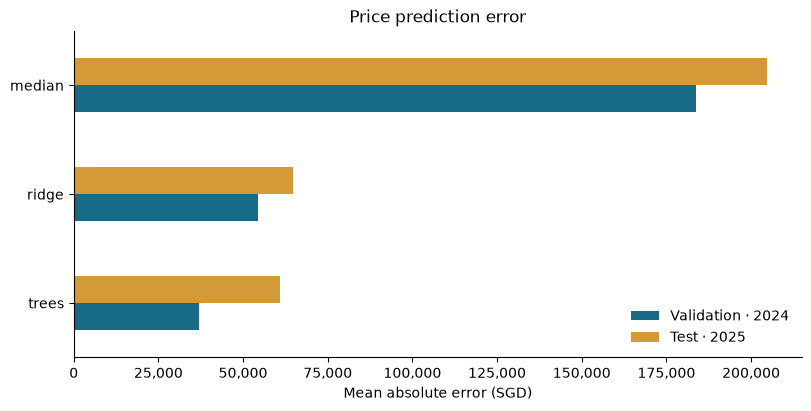

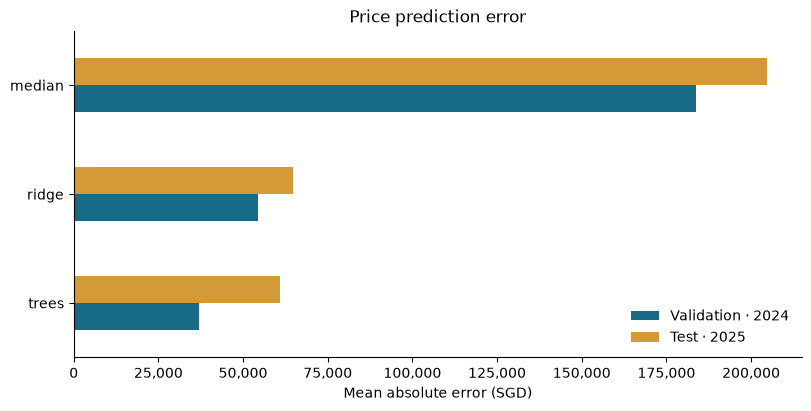

In [4]:
figure = plot_comparison(comparison)
figure

## Decision

Use validation MAE to compare this fixed experiment with Ridge. Final test scores describe later-period generalisation; they do not select the configuration. Per-town, flat-type, storey, and month metrics are saved beside the model bundle.